# Baseline — Regressão Logística

Este notebook tem como objetivo construir um modelo baseline para prever o churn de clientes.

A Regressão Logística foi escolhida por ser um modelo simples, rápido e interpretável para problemas de classificação binária. O resultado será usado como referência para comparação com modelos mais complexos nas próximas etapas.

## 1. Objetivos

- Preparar as variáveis numéricas e categóricas;
- Separar os dados em treino e teste;
- Treinar uma Regressão Logística;
- Avaliar o modelo com métricas de classificação;
- Identificar limitações e possíveis melhorias.

## 2. Importações

In [49]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
    RocCurveDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
TARGET = "Churn Value"

## 3. Carregamento dos dados

In [50]:
DATA_PATH = Path("../data/processed/dataset.parquet")

df = pd.read_parquet(DATA_PATH)

print(f"Dimensões: {df.shape}")
df.head()

Dimensões: (7043, 33)


,CustomerID,Count,Country,State,City,Zip Code,Lat Long,Latitude,Longitude,Gender,...,Contract,Paperless Billing,Payment Method,Monthly Charges,Total Charges,Churn Label,Churn Value,Churn Score,CLTV,Churn Reason
0,3668-QPYBK,1,United States,California,Los Angeles,90003,"33.964131, -118.272783",33.964131,-118.272783,Male,...,Month-to-month,Yes,Mailed check,53.85,108.15,Yes,1,86,3239,Competitor made better offer
1,9237-HQITU,1,United States,California,Los Angeles,90005,"34.059281, -118.30742",34.059281,-118.307420,Female,...,Month-to-month,Yes,Electronic check,70.70,151.65,Yes,1,67,2701,Moved
2,9305-CDSKC,1,United States,California,Los Angeles,90006,"34.048013, -118.293953",34.048013,-118.293953,Female,...,Month-to-month,Yes,Electronic check,99.65,820.50,Yes,1,86,5372,Moved
3,7892-POOKP,1,United States,California,Los Angeles,90010,"34.062125, -118.315709",34.062125,-118.315709,Female,...,Month-to-month,Yes,Electronic check,104.80,3046.05,Yes,1,84,5003,Moved
4,0280-XJGEX,1,United States,California,Los Angeles,90015,"34.039224, -118.266293",34.039224,-118.266293,Male,...,Month-to-month,Yes,Bank transfer (automatic),103.70,5036.30,Yes,1,89,5340,Competitor had better devices


In [51]:
assert TARGET in df.columns, f"A coluna target '{TARGET}' não foi encontrada."
assert df[TARGET].isna().sum() == 0, "O target contém valores ausentes."

df[TARGET].value_counts(dropna=False)

Churn Value
0    5174
1    1869
Name: count, dtype: int64

## 4. Separação entre features e target

In [52]:
columns_to_drop = [
    TARGET,
    "CustomerID",
    "Churn Label",
    "Churn Score",
    "Churn Reason",
    "Count",
    "Country",
    "State",
    "City",
    "Zip Code",
    "Lat Long",
    "Latitude",
    "Longitude",
]

columns_to_drop = [
    column for column in columns_to_drop
    if column in df.columns
]

X = df.drop(columns=columns_to_drop)
y = df[TARGET].astype(int)

print(f"Features: {X.shape}")
print(f"Target: {y.shape}")

Features: (7043, 20)
Target: (7043,)


## 5. Divisão em treino e teste

In [53]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

print(f"Treino: {X_train.shape}")
print(f"Teste: {X_test.shape}")

Treino: (5634, 20)
Teste: (1409, 20)


In [54]:
distribution = pd.DataFrame({
    "Treino": y_train.value_counts(normalize=True),
    "Teste": y_test.value_counts(normalize=True),
}).sort_index()

distribution

,Treino,Teste
Churn Value,,
0,0.734647,0.734564
1,0.265353,0.265436


## 6. Identificação dos tipos de variáveis

In [55]:
numeric_columns = X_train.select_dtypes(
    include=["number"]
).columns.tolist()

categorical_columns = X_train.select_dtypes(
    exclude=["number"]
).columns.tolist()

print(f"Variáveis numéricas ({len(numeric_columns)}):")
print(numeric_columns)

print(f"\nVariáveis categóricas ({len(categorical_columns)}):")
print(categorical_columns)

Variáveis numéricas (4):
['Tenure Months', 'Monthly Charges', 'Total Charges', 'CLTV']

Variáveis categóricas (16):
['Gender', 'Senior Citizen', 'Partner', 'Dependents', 'Phone Service', 'Multiple Lines', 'Internet Service', 'Online Security', 'Online Backup', 'Device Protection', 'Tech Support', 'Streaming TV', 'Streaming Movies', 'Contract', 'Paperless Billing', 'Payment Method']


## 7. Pré-processamento

In [56]:
numeric_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
    ]
)

categorical_preprocessor = Pipeline(
    steps=[
        ("imputer", SimpleImputer(strategy="most_frequent")),
        (
            "one_hot",
            OneHotEncoder(
                handle_unknown="ignore",
                drop="if_binary",
            ),
        ),
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", numeric_preprocessor, numeric_columns),
        ("categorical", categorical_preprocessor, categorical_columns),
    ]
)

## 8. Construção e treinamento do baseline

In [57]:
baseline_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1_000,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)

baseline_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](20,)","['Gender','Senior Citizen','Partner',...,'Monthly Charges','Total Charges', 'CLTV']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,20
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('numeric', ...), ('categorical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``re

## 9. Predições

In [58]:
y_pred = baseline_model.predict(X_test)
y_pred_proba = baseline_model.predict_proba(X_test)[:, 1]

## 10. Métricas

### Métricas de avaliação

#### Métrica técnica principal: F1-score

O F1-score da classe churn será utilizado como métrica técnica principal,
pois combina precision e recall. Essa escolha considera tanto a capacidade
de identificar clientes propensos ao cancelamento quanto a necessidade de
evitar um número excessivo de falsos positivos.

A ROC-AUC será utilizada como métrica complementar para avaliar a capacidade
do modelo de ordenar clientes entre menor e maior risco de churn.

O recall também será acompanhado, pois falsos negativos representam clientes
que cancelariam o serviço, mas não seriam selecionados para uma possível ação
de retenção.

### Métrica de negócio: valor líquido da campanha de retenção

A métrica de negócio proposta é o valor líquido estimado das ações de
retenção. Ela deverá comparar o valor financeiro preservado com clientes
corretamente identificados e retidos com o custo de abordar todos os clientes
classificados como propensos ao churn.

Valor líquido = receita preservada − custo das ações de retenção.

O dataset atual não possui informações sobre o custo de cada abordagem nem
sobre a taxa de sucesso das ações de retenção. Portanto, nesta primeira etapa,
o recall da classe churn será utilizado como uma aproximação operacional da
capacidade de alcançar clientes em risco.

Em produção, deverão ser coletados:

- Custo médio da ação de retenção;
- Taxa de aceite da oferta;
- Quantidade de clientes efetivamente retidos;
- Receita ou valor preservado após a retenção.

In [59]:
baseline_metrics = pd.DataFrame({
    "Métrica": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC",
    ],
    "Valor": [
        accuracy_score(y_test, y_pred),
        precision_score(y_test, y_pred, zero_division=0),
        recall_score(y_test, y_pred, zero_division=0),
        f1_score(y_test, y_pred, zero_division=0),
        roc_auc_score(y_test, y_pred_proba),
    ],
})

baseline_metrics.style.format({"Valor": "{:.4f}"})

,Métrica,Valor
0,Accuracy,0.8034
1,Precision,0.6456
2,Recall,0.5749
3,F1-score,0.6082
4,ROC-AUC,0.8488


In [60]:
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["Não churn", "Churn"],
        zero_division=0,
    )
)

              precision    recall  f1-score   support

   Não churn       0.85      0.89      0.87      1035
       Churn       0.65      0.57      0.61       374

    accuracy                           0.80      1409
   macro avg       0.75      0.73      0.74      1409
weighted avg       0.80      0.80      0.80      1409



## 11. Matriz de confusão

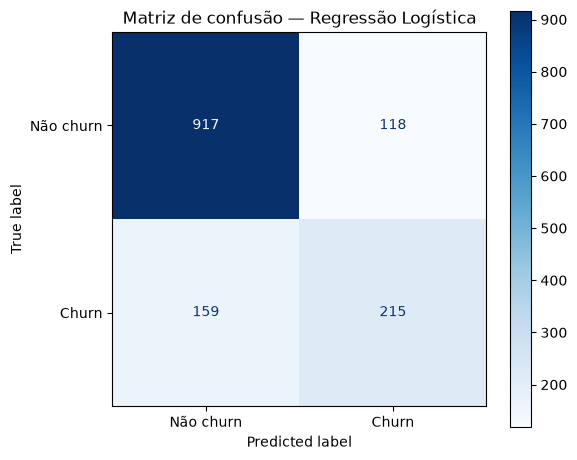

In [61]:
fig, ax = plt.subplots(figsize=(6, 5))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Não churn", "Churn"],
    cmap="Blues",
    values_format="d",
    ax=ax,
)

ax.set_title("Matriz de confusão — Regressão Logística")
plt.tight_layout()
plt.show()

## 12. Curva ROC

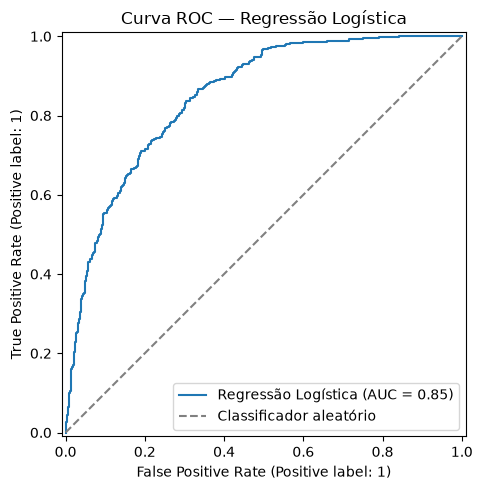

In [62]:
fig, ax = plt.subplots(figsize=(7, 5))

RocCurveDisplay.from_predictions(
    y_test,
    y_pred_proba,
    name="Regressão Logística",
    ax=ax,
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Classificador aleatório",
)

ax.set_title("Curva ROC — Regressão Logística")
ax.legend()
plt.tight_layout()
plt.show()

## 13. Conclusão inicial

### Conclusão

A Regressão Logística foi utilizada como modelo baseline para a previsão de
churn. Foram removidas variáveis identificadoras, variáveis com vazamento do
target, colunas constantes e atributos geográficos redundantes.

O modelo obteve:

- Accuracy: `0,8034`;
- Precision para churn: `0,6456`;
- Recall para churn: `0,5749`;
- F1-score para churn: `0,6082`;
- ROC-AUC: `0,8488`.

Os resultados mostram que o modelo possui boa capacidade de diferenciar
clientes com maior e menor risco de churn. O desempenho também foi superior
ao de uma estratégia ingênua que classificasse todos os clientes como não
churn, cuja acurácia seria de aproximadamente 73,46%.

Apesar disso, o recall indica que o modelo identificou cerca de 57,5% dos
clientes que efetivamente cancelaram o serviço. Isso significa que
aproximadamente 42,5% dos casos reais de churn ainda não foram detectados.

O modelo será mantido como baseline para comparação com experimentos
posteriores, incluindo ajuste do limiar de classificação, tratamento do
desbalanceamento, validação cruzada, ajuste de hiperparâmetros e comparação
com outros algoritmos.